# 06 · Entrenamiento y ajuste de hiperparámetros

**Objetivo:** encontrar, para cada red (RNN simple, LSTM y GRU) y cada horizonte (5, 63 y 252 días), la configuración que mejor predice, en **condiciones idénticas** para las tres y validando siempre sobre años que la red no ha visto.

Este notebook **no entrena nada**: lee los resultados que genera

```bash
poetry run python scripts/tune.py --all      # 9 estudios (3 redes × 3 horizontes) en paralelo
```

y que se guardan en `reports/tuning/`: `*_trials.csv` (todos los ensayos) y `*_best.json` (la mejor configuración).

**Contenido**
1. Cómo funciona cada red por dentro
2. Las reglas del juego: condiciones iguales para las tres
3. Registro completo de experimentos
4. Evolución de la búsqueda
5. Configuraciones ganadoras y su arquitectura
6. Resultado por año de validación
7. ¿Qué hiperparámetros funcionan?
8. Conclusiones y siguiente paso

> **Nota:** este notebook documenta la **ronda 1** del ajuste (`reports/tuning/ronda_1/`). Después sí se hicieron más rondas, incluida la segunda búsqueda que aquí se descarta. Están todas resumidas en el notebook 08 (registro de experimentos).

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import NullFormatter

from oil_forecast.config import HORIZONS, N_TRIALS, tuning_dir

TUNING_DIR = tuning_dir(1)  # this notebook documents the first search (round 1)
from oil_forecast.models import CELLS
from oil_forecast.plotting import CELL_NAMES, COLORS, draw_architecture, draw_cell, set_style

set_style()
pd.set_option("display.float_format", "{:.3f}".format)
NETS = list(CELL_NAMES.values())

trials, best = [], {}
for cell in CELLS:
    for hname, h in HORIZONS.items():
        t = pd.read_csv(TUNING_DIR / f"{cell}_h{h}_trials.csv")
        t["celda"], t["red"], t["horizonte"] = cell, CELL_NAMES[cell], hname
        trials.append(t)
        best[(CELL_NAMES[cell], hname)] = json.loads((TUNING_DIR / f"{cell}_h{h}_best.json").read_text())
trials = pd.concat(trials, ignore_index=True)
FOLDS = sorted(c.replace("user_attrs_rel_rmse_", "") for c in trials.columns if c.startswith("user_attrs_rel_rmse_"))
print(f"{len(trials)} ensayos en {len(best)} estudios · presupuesto: {N_TRIALS[1]} ensayos terminados por estudio")

180 ensayos en 9 estudios · presupuesto: 20 ensayos terminados por estudio


## 1. Cómo funciona cada red por dentro

Las tres redes leen la secuencia de 60 días **día a día** y van actualizando un **estado oculto** *h* que resume lo visto hasta ese momento. La diferencia está en *cómo* actualizan ese estado:

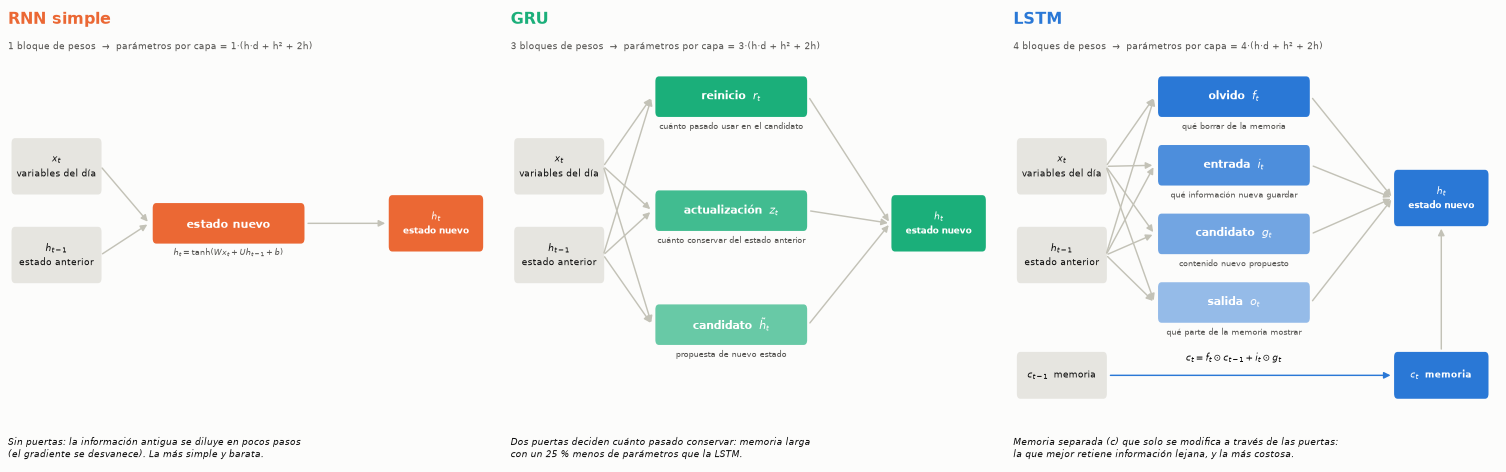

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for ax, cell in zip(axes, ["rnn", "gru", "lstm"]):
    draw_cell(ax, cell)
plt.tight_layout()

- La **RNN simple** mezcla la entrada y el estado anterior en una sola operación. Es barata, pero al repetir esa operación 60 veces la información de los primeros días se va borrando.
- La **GRU** añade dos **puertas** (pequeñas redes con salida entre 0 y 1) que deciden cuánto del estado anterior se conserva y cuánto se sustituye.
- La **LSTM** tiene además una **memoria separada** (*c*) por la que la información puede viajar muchos pasos casi sin alterarse; tres puertas controlan qué se borra, qué se añade y qué se muestra.

Con el mismo tamaño de capa (*h* neuronas y *d* = 16 variables de entrada), la GRU tiene unas **3 veces** los parámetros de la RNN y la LSTM **4 veces**. Más capacidad de memoria también significa más riesgo de memorizar ruido con pocos datos: por eso no está claro de antemano cuál ganará.

## 2. Las reglas del juego: condiciones iguales para las tres

| Elemento | Valor (igual para RNN, LSTM y GRU) |
|---|---|
| Datos | 16 variables (notebook 03), ventana de **60 días** |
| Objetivo | retorno log a *h* días, estandarizado con la media y desviación del train |
| Arquitectura | capa(s) recurrente(s) → dropout → capa lineal sobre el último estado oculto (**solo cambia la celda**) |
| Validación | walk-forward, ventana de entrenamiento creciente, un bloque por año (2019-2023) y **embargo de *h* días** |
| Parada temprana | último 15 % del train de cada fold (con embargo); **nunca** el año que se evalúa |
| Optimizador | Adam, recorte del gradiente a norma 1, máximo 150 épocas, paciencia 15 |
| Espacio de búsqueda | neuronas {16, 32, 64, 128} · capas {1, 2} · dropout [0, 0,5] · *learning rate* [10⁻⁴, 3·10⁻³] · lote {64, 128, 256} · *weight decay* [10⁻⁶, 10⁻³] · pérdida {MSE, Huber} |
| Presupuesto | **20 ensayos terminados** por red y horizonte, muestreador TPE con la misma semilla y el mismo primer ensayo (configuración por defecto) |
| Poda | un ensayo se abandona si tras sus primeros años va peor que la mediana de los anteriores |
| Métrica | media por año de **RMSE(red) / RMSE(ingenuo)**, con precios en dólares |
| Hardware | CPU, 1 hilo por modelo |

**Cómo leer la métrica:** 1,00 = igual que suponer que el precio no cambia; 0,95 = un 5 % menos de error; 1,10 = un 10 % peor. Se divide por el ingenuo **de cada año** para que los años muy volátiles (2020, 2022) no dominen la media.

**¿Qué es un ensayo?** Optuna propone una configuración, se entrena la red una vez por año de validación (hasta 5 entrenamientos) y se anota el error medio. Con lo aprendido de los ensayos anteriores (muestreador TPE) propone el siguiente, concentrándose en las zonas prometedoras.

## 3. Registro completo de experimentos

Todas las configuraciones probadas, ordenadas de mejor a peor. Los ensayos **podados** (`PRUNED`) se abandonaron tras los primeros años por ir claramente peor; su media es parcial.

In [3]:
COLS = {"number": "ensayo", "state": "estado", "value": "RMSE rel. medio",
        "params_hidden_size": "neuronas", "params_num_layers": "capas", "params_dropout": "dropout",
        "params_lr": "learning rate", "params_batch_size": "lote", "params_weight_decay": "weight decay",
        "params_loss": "pérdida", "user_attrs_n_params": "parámetros", "user_attrs_mean_train_time_s": "s / fold"}

def experiment_log(red, hname):
    t = trials[(trials.red == red) & (trials.horizonte == hname)].copy()
    folds = [f"user_attrs_rel_rmse_{f}" for f in FOLDS if f"user_attrs_rel_rmse_{f}" in t]
    t["value"] = t["value"].fillna(t[folds].mean(axis=1))
    out = t[list(COLS) + folds].rename(columns=COLS | {f: f.replace("user_attrs_rel_rmse_", "") for f in folds})
    out["estado"] = out["estado"].map({"COMPLETE": "completo", "PRUNED": "podado"})
    out = out.sort_values(["estado", "RMSE rel. medio"]).set_index("ensayo")
    year_cols = [c for c in out.columns if c.isdigit()]
    return (out.style
            .format({"RMSE rel. medio": "{:.3f}", "dropout": "{:.2f}", "learning rate": "{:.1e}", "weight decay": "{:.1e}",
                     "parámetros": "{:,.0f}", "s / fold": "{:.1f}", "neuronas": "{:.0f}", "capas": "{:.0f}", "lote": "{:.0f}",
                     **{c: "{:.2f}" for c in year_cols}}, na_rep="—")
            .background_gradient(subset=["RMSE rel. medio"] + year_cols, cmap="RdYlGn_r", vmin=0.85, vmax=1.15))

for hname, h in HORIZONS.items():
    display(Markdown(f"### Horizonte {hname} ({h} días)"))
    for red in NETS:
        b = best[(red, hname)]
        display(Markdown(f"**{red}** · mejor ensayo: nº {b['trial']} con RMSE relativo **{b['value']:.3f}**"))
        display(experiment_log(red, hname))

### Horizonte corto (5 días)

**RNN simple** · mejor ensayo: nº 19 con RMSE relativo **0.994**

,estado,RMSE rel. medio,neuronas,capas,dropout,learning rate,lote,weight decay,pérdida,parámetros,s / fold,2019,2020,2021,2022,2023
ensayo,,,,,,,,,,,,,,,,
19,completo,0.994,16,1,0.36,8.3e-04,128,1.4e-05,huber,561,7.0,0.99,0.99,1.00,0.99,1.00
16,completo,0.995,16,1,0.34,3.2e-04,128,7.1e-06,huber,561,15.8,0.99,0.99,1.00,0.99,1.00
17,completo,0.995,16,1,0.43,8.3e-04,128,8.0e-06,huber,561,7.6,0.99,0.99,1.00,0.99,1.00
14,completo,0.996,16,1,0.33,1.3e-04,128,1.9e-05,huber,561,27.6,0.99,0.99,1.00,1.00,1.00
13,completo,0.997,16,1,0.26,1.0e-04,128,1.8e-05,huber,561,30.2,0.99,0.99,1.00,1.00,1.00
15,completo,0.997,16,1,0.14,2.2e-04,128,2.5e-05,huber,561,15.4,0.99,0.99,1.00,1.00,1.00
20,completo,0.999,16,1,0.28,1.1e-03,64,6.3e-05,huber,561,7.8,0.99,1.00,1.01,0.99,1.00
12,completo,0.999,16,1,0.20,1.2e-04,128,9.8e-06,mse,561,27.8,0.99,1.00,1.01,1.00,1.00
11,completo,1.000,16,1,0.23,1.2e-04,128,3.4e-06,mse,561,30.1,0.99,1.00,1.01,1.00,1.00


**LSTM** · mejor ensayo: nº 12 con RMSE relativo **0.997**

,estado,RMSE rel. medio,neuronas,capas,dropout,learning rate,lote,weight decay,pérdida,parámetros,s / fold,2019,2020,2021,2022,2023
ensayo,,,,,,,,,,,,,,,,
12,completo,0.997,64,2,0.22,1.1e-04,128,1.7e-05,huber,"54,337",42.1,0.99,1.00,0.99,1.00,1.00
20,completo,0.998,64,2,0.30,1.1e-04,128,6.6e-04,huber,"54,337",33.1,1.00,1.00,0.99,1.00,1.00
16,completo,0.998,64,2,0.21,1.6e-04,128,1.1e-06,huber,"54,337",26.9,0.99,1.00,0.99,1.00,1.00
17,completo,0.998,64,2,0.17,1.9e-04,128,1.2e-06,huber,"54,337",25.6,1.00,1.00,0.99,1.00,1.00
3,completo,0.998,64,2,0.09,1.2e-04,128,8.2e-06,huber,"54,337",60.5,0.99,1.00,0.99,1.00,1.00
8,completo,0.998,64,2,0.09,1.2e-04,128,8.2e-06,huber,"54,337",52.5,0.99,1.00,0.99,1.00,1.00
11,completo,0.999,64,2,0.38,2.2e-04,128,6.1e-04,huber,"54,337",39.8,0.99,1.00,0.99,1.00,1.01
14,completo,0.999,64,2,0.01,1.3e-04,128,6.8e-05,mse,"54,337",33.1,0.99,1.00,1.00,1.01,1.00
9,completo,1.000,64,2,0.07,2.6e-04,128,3.3e-04,huber,"54,337",39.7,0.99,1.00,0.99,1.00,1.01


**GRU** · mejor ensayo: nº 1 con RMSE relativo **0.998**

... (11 outputs left out)

**LSTM** · mejor ensayo: nº 3 con RMSE relativo **0.980**

,estado,RMSE rel. medio,neuronas,capas,dropout,learning rate,lote,weight decay,pérdida,parámetros,s / fold,2019,2020,2021,2022,2023
ensayo,,,,,,,,,,,,,,,,
3,completo,0.980,64,2,0.09,1.2e-04,128,8.2e-06,huber,"54,337",54.9,1.46,0.81,1.11,0.54,—
12,completo,0.990,16,1,0.11,1.2e-04,128,3.6e-05,mse,"2,193",25.1,1.16,0.80,1.13,0.87,—
16,completo,1.003,16,1,0.16,3.0e-04,128,1.2e-05,huber,"2,193",11.7,1.22,0.79,1.07,0.94,—
14,completo,1.006,16,1,0.11,1.1e-04,128,1.2e-05,mse,"2,193",24.2,1.17,0.80,1.14,0.91,—
5,completo,1.006,16,1,0.10,1.2e-04,128,3.1e-04,mse,"2,193",24.0,1.18,0.80,1.14,0.90,—
4,completo,1.020,64,2,0.13,9.5e-04,256,3.6e-06,mse,"54,337",33.8,1.39,0.83,1.12,0.74,—
6,completo,1.035,64,2,0.39,2.0e-04,128,1.5e-04,mse,"54,337",52.5,1.49,0.79,1.16,0.69,—
2,completo,1.042,128,2,0.22,2.7e-04,64,1.3e-05,huber,"206,977",84.2,1.33,0.84,1.09,0.91,—
1,completo,1.070,32,1,0.08,1.2e-04,64,1.2e-06,mse,"6,433",18.6,1.26,0.87,1.54,0.62,—


**GRU** · mejor ensayo: nº 14 con RMSE relativo **1.095**

,estado,RMSE rel. medio,neuronas,capas,dropout,learning rate,lote,weight decay,pérdida,parámetros,s / fold,2019,2020,2021,2022,2023
ensayo,,,,,,,,,,,,,,,,
14,completo,1.095,64,2,0.02,1.4e-04,128,5.1e-04,mse,"40,769",45.1,1.49,0.75,1.05,1.09,—
13,completo,1.103,64,2,0.12,2.9e-04,256,3.8e-04,mse,"40,769",42.3,1.52,0.71,1.06,1.13,—
6,completo,1.114,64,2,0.39,2.0e-04,128,1.5e-04,mse,"40,769",53.4,1.52,0.75,1.05,1.14,—
15,completo,1.114,64,2,0.03,1.3e-04,256,3.5e-04,mse,"40,769",44.7,1.49,0.75,1.05,1.16,—
12,completo,1.121,64,2,0.20,4.6e-04,256,2.8e-04,mse,"40,769",42.4,1.52,0.74,1.02,1.19,—
4,completo,1.130,64,2,0.13,9.5e-04,256,3.6e-06,mse,"40,769",33.4,1.52,0.75,1.00,1.26,—
3,completo,1.147,64,2,0.09,1.2e-04,128,8.2e-06,huber,"40,769",58.9,1.50,0.77,0.97,1.35,—
0,completo,1.155,32,1,0.20,1.0e-03,128,1.0e-05,mse,"4,833",8.0,1.59,0.82,1.07,1.15,—
9,completo,1.157,64,2,0.40,1.1e-03,128,9.2e-05,mse,"40,769",37.3,1.49,0.81,1.02,1.31,—


## 4. Evolución de la búsqueda

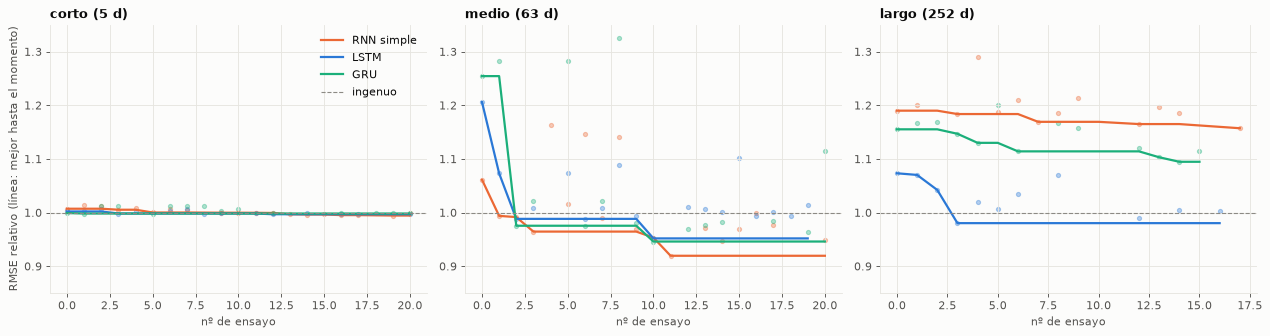

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, hname in zip(axes, HORIZONS):
    for red in NETS:
        t = trials[(trials.horizonte == hname) & (trials.red == red)].sort_values("number")
        done = t[t.state == "COMPLETE"]
        ax.scatter(done["number"], done["value"], s=14, color=COLORS[red], alpha=0.35)
        ax.plot(done["number"], done["value"].cummin(), color=COLORS[red], label=red)
    ax.axhline(1, color=COLORS["Ingenuo"], ls="--", lw=1, label="ingenuo")
    ax.set_title(f"{hname} ({HORIZONS[hname]} d)"); ax.set_xlabel("nº de ensayo")
    ax.set_ylim(0.85, 1.35)
axes[0].set_ylabel("RMSE relativo (línea: mejor hasta el momento)")
axes[0].legend(loc="upper right")
plt.tight_layout()

**Qué se ve:**
- **5 días:** las curvas son planas desde el primer ensayo. La configuración por defecto ya llega al techo (≈ 1,00): cualquier red acaba aprendiendo que lo mejor es predecir casi "sin cambio". Ninguna configuración mejora al ingenuo más de un 0,6 %.
- **63 días:** las tres redes bajan de 1 en los primeros 10-12 ensayos y se estabilizan: **RNN simple 0,919**, **GRU 0,946**, **LSTM 0,952**.
- **252 días:** solo la **LSTM** consigue bajar de 1 (0,980). La RNN simple (1,157) y la GRU (1,095) no encuentran ninguna configuración que bata al ingenuo: a un año vista es mucho más fácil empeorar que mejorar.

## 5. Configuraciones ganadoras y su arquitectura

In [5]:
rows = []
for (red, hname), b in best.items():
    rows.append({"horizonte": hname, "red": red, "RMSE relativo": b["value"], "ensayo": b["trial"],
                 "neuronas": b["params"]["hidden_size"], "capas": b["params"]["num_layers"],
                 "dropout": b["params"]["dropout"], "learning rate": b["params"]["lr"],
                 "lote": b["params"]["batch_size"], "weight decay": b["params"]["weight_decay"],
                 "pérdida": b["params"]["loss"], "parámetros": b["user_attrs"]["n_params"],
                 "s / fold": b["user_attrs"]["mean_train_time_s"]})
best_table = pd.DataFrame(rows)
best_table["horizonte"] = pd.Categorical(best_table["horizonte"], list(HORIZONS), ordered=True)
best_table = best_table.sort_values(["horizonte", "red"]).set_index(["horizonte", "red"])
(best_table.style.format({"RMSE relativo": "{:.3f}", "dropout": "{:.2f}", "learning rate": "{:.1e}",
                          "weight decay": "{:.1e}", "parámetros": "{:,.0f}", "s / fold": "{:.1f}"})
 .background_gradient(subset=["RMSE relativo"], cmap="RdYlGn_r", vmin=0.9, vmax=1.1))

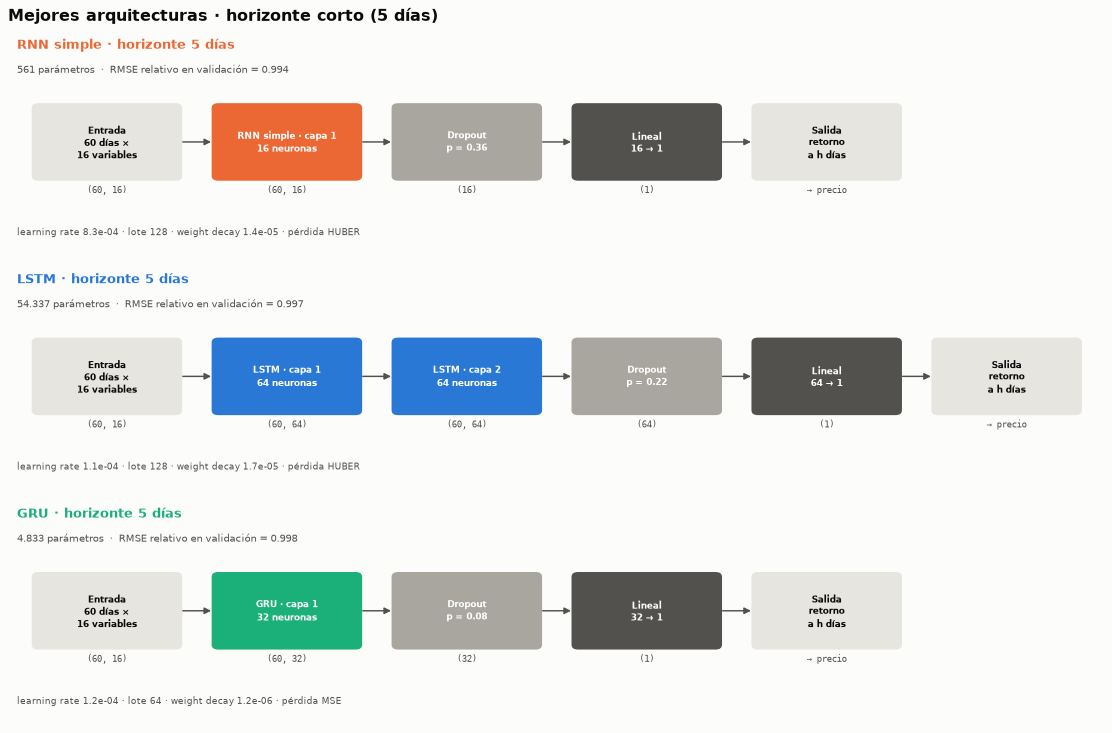

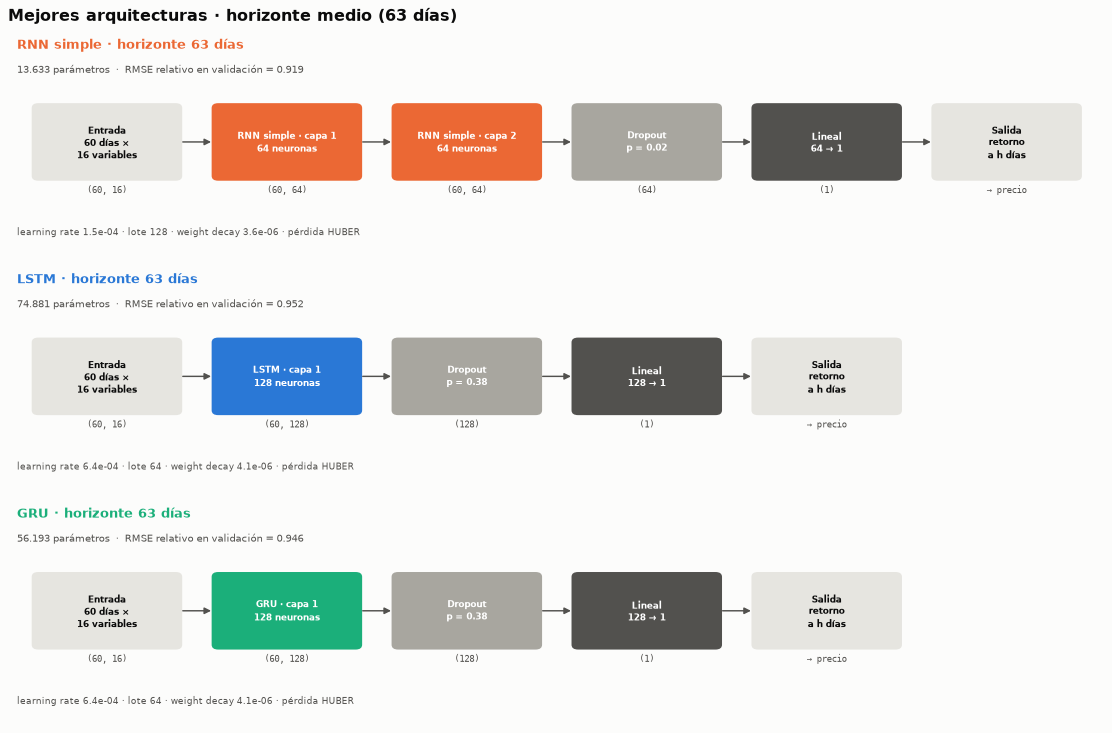

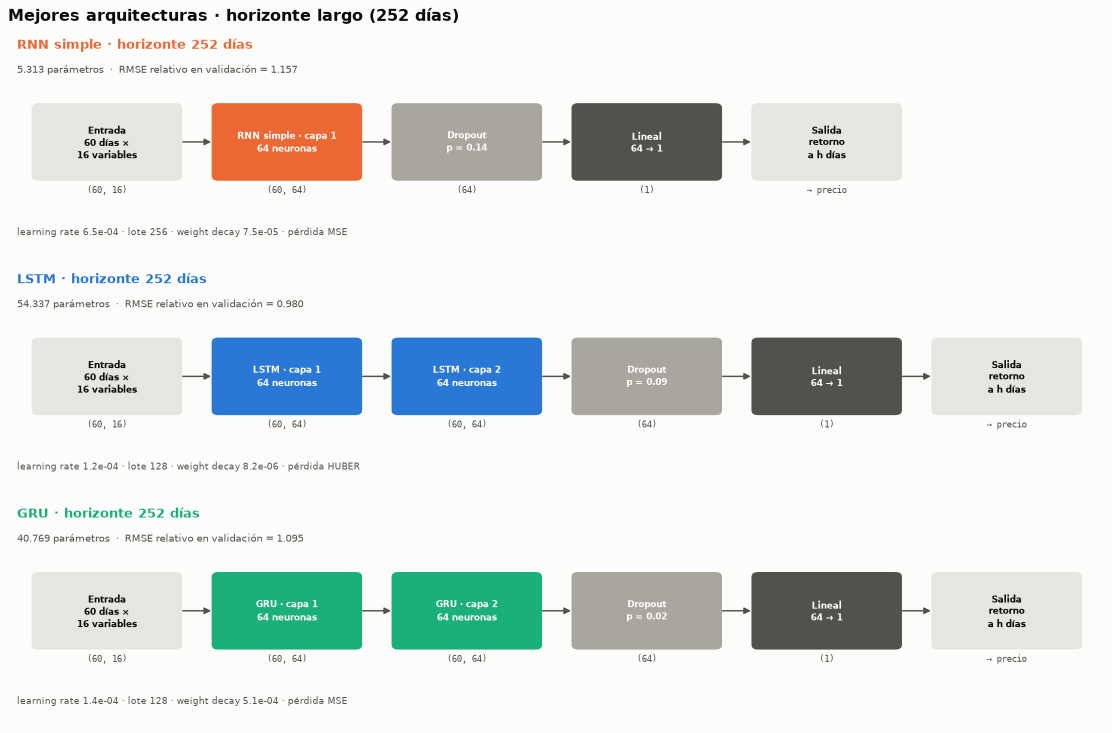

In [6]:
for hname, h in HORIZONS.items():
    fig, axes = plt.subplots(3, 1, figsize=(14, 9.3))
    for ax, cell in zip(axes, CELLS):
        b = best[(CELL_NAMES[cell], hname)]
        draw_architecture(ax, cell, b["params"], b["user_attrs"]["n_params"], horizon=h, score=b["value"])
    fig.suptitle(f"Mejores arquitecturas · horizonte {hname} ({h} días)", x=0.01, ha="left", fontsize=14, weight="bold")
    plt.tight_layout()
    plt.show()

**Patrones de las configuraciones ganadoras:**
- **5 días:** ganan redes que apenas se mueven de la media: la RNN más pequeña posible (16 neuronas, 561 parámetros) con mucho dropout, o redes con un *learning rate* mínimo. Es la forma que tiene la red de "rendirse" ante un horizonte sin señal.
- **63 días:** la mejor es la **RNN simple de 2 capas × 64 neuronas** (13.633 parámetros). La LSTM y la GRU eligieron **exactamente la misma configuración** (1 capa de 128 neuronas, dropout 0,38): el muestreador usa la misma semilla para las tres redes, así que propone las mismas configuraciones mientras los resultados se parecen. Es una consecuencia directa de las condiciones iguales y hace la comparación aún más limpia, porque ahí **solo cambia la celda**.
- **Pérdida de Huber en 6 de las 9 ganadoras:** al ser menos sensible a los errores enormes (2020, 2022), evita que unos pocos días extremos dominen el entrenamiento.
- **Más parámetros no implica mejor resultado:** a 63 días la RNN gana con 4-5 veces menos parámetros que la LSTM y la GRU.

## 6. Resultado por año de validación

Una media puede esconder que un modelo gana mucho un año y pierde otro. Mapa del RMSE relativo de cada configuración ganadora en cada año (verde = mejor que el ingenuo).

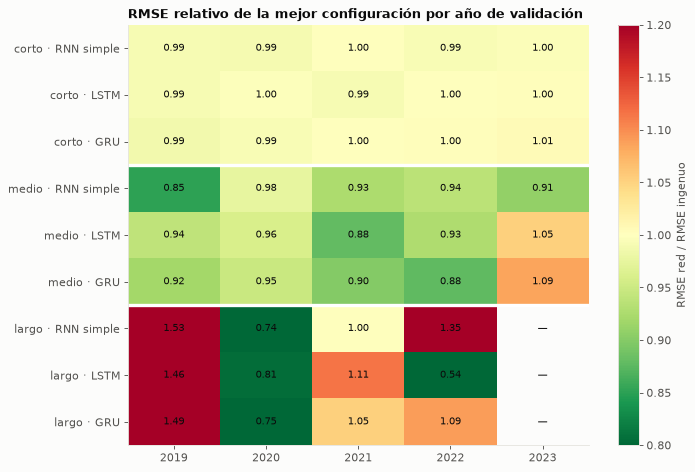

In [7]:
per_fold = pd.DataFrame({(red, hname): {k.replace("rel_rmse_", ""): v for k, v in b["user_attrs"].items()
                                         if k.startswith("rel_rmse_")} for (red, hname), b in best.items()}).T
per_fold = per_fold.loc[[(r, h) for h in HORIZONS for r in NETS]]
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(per_fold, cmap="RdYlGn_r", vmin=0.8, vmax=1.2, aspect="auto")
ax.set_xticks(range(per_fold.shape[1]), per_fold.columns)
ax.set_yticks(range(per_fold.shape[0]), [f"{h} · {r}" for r, h in per_fold.index])
for i in range(per_fold.shape[0]):
    for j in range(per_fold.shape[1]):
        v = per_fold.iloc[i, j]
        ax.text(j, i, "—" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", fontsize=9)
for y in (2.5, 5.5):
    ax.axhline(y, color="white", lw=3)
ax.grid(False); fig.colorbar(im, label="RMSE red / RMSE ingenuo")
ax.set_title("RMSE relativo de la mejor configuración por año de validación")
plt.tight_layout()

**Lectura año a año:**
- **5 días:** todos los años entre 0,99 y 1,01. Sin sorpresas.
- **63 días:** la **RNN simple mejora al ingenuo los 5 años** (0,85-0,98), que es justo lo que buscamos: estabilidad. La LSTM y la GRU ganan en 2019-2022 pero **pierden en 2023** (1,05 y 1,09).
- **252 días:** el resultado depende de **cuatro episodios macroeconómicos**:
  - **2019 (≈1,5 en las tres):** desde 2019 se predice 2020 y llega el desplome de la pandemia, imposible de anticipar.
  - **2020 (0,74-0,81):** tras el desplome, la volatilidad alta y el precio hundido anticipan correctamente el rebote de 2021.
  - **2022:** la LSTM acierta (0,54) y la RNN simple falla (1,35).

  Con tan pocos episodios independientes, la diferencia entre redes a un año vista es en gran parte **suerte**: hay que tomarla con mucha cautela.

## 7. ¿Qué hiperparámetros funcionan?

Todos los ensayos completos, por horizonte. Cada punto es un ensayo (color = red); la línea discontinua es el ingenuo.

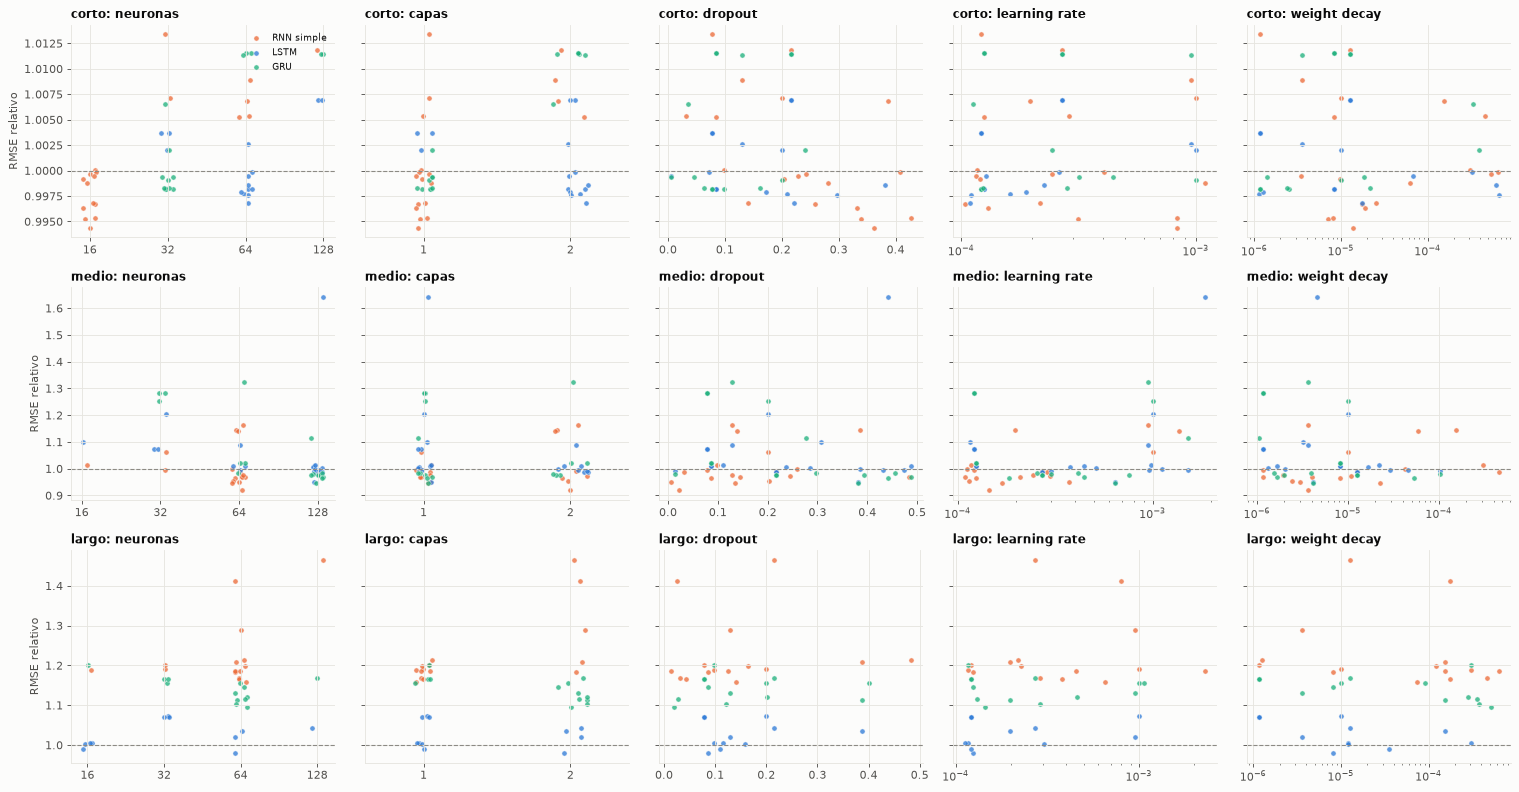

In [8]:
done = trials[trials.state == "COMPLETE"]
params = [("params_hidden_size", "neuronas", False), ("params_num_layers", "capas", False),
          ("params_dropout", "dropout", False), ("params_lr", "learning rate", True),
          ("params_weight_decay", "weight decay", True)]
fig, axes = plt.subplots(3, 5, figsize=(19, 10), sharey="row")
rng = np.random.default_rng(0)
for row, hname in zip(axes, HORIZONS):
    d = done[done.horizonte == hname]
    for ax, (col, label, log) in zip(row, params):
        for red in NETS:
            g = d[d.red == red]
            x = g[col].astype(float)
            if col in ("params_hidden_size", "params_num_layers"):
                x = x * (1 + rng.uniform(-0.06, 0.06, len(x)))
            ax.scatter(x, g["value"], s=22, color=COLORS[red], alpha=0.75, label=red, edgecolor="white", linewidth=0.5)
        ax.axhline(1, color=COLORS["Ingenuo"], ls="--", lw=1)
        if col == "params_hidden_size":
            ax.set_xscale("log", base=2); ax.set_xticks([16, 32, 64, 128], ["16", "32", "64", "128"])
            ax.xaxis.set_minor_formatter(NullFormatter())
        elif col == "params_num_layers":
            ax.set_xticks([1, 2]); ax.set_xlim(0.6, 2.4)
        elif log:
            ax.set_xscale("log"); ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_title(f"{hname}: {label}", fontsize=11)
    row[0].set_ylabel("RMSE relativo")
axes[0, 0].legend(loc="upper right", fontsize=8)
plt.tight_layout()

In [9]:
loss_tbl = done.groupby(["horizonte", "params_loss"])["value"].agg(["count", "median", "min"]).unstack("params_loss")
loss_tbl.loc[list(HORIZONS)]

count     median         min      
params_loss huber mse  huber   mse huber   mse
horizonte                                     
corto          23  26  0.998 1.000 0.994 0.998
medio          38  15  0.986 1.146 0.919 0.989
largo           8  31  1.157 1.157 0.980 0.990

**Qué hiperparámetros funcionan** (correlación de Spearman entre cada hiperparámetro y el error, con todos los ensayos completos):
- ***Learning rate* bajo en los tres horizontes** (ρ ≈ +0,2: cuanto más alto, peor). Aprender despacio con parada temprana actúa como regularización.
- **El tamaño ideal depende del horizonte:** a 5 y 252 días ganan las redes **pequeñas** (16 neuronas en casi todos los mejores ensayos; ρ = +0,49 y +0,24), porque hay poca señal que aprender. A 63 días ganan las **grandes** (64-128 neuronas; ρ = −0,38), porque sí hay patrones que capturar.
- **Pérdida de Huber:** a 63 días su mediana es 0,986 frente a 1,146 con MSE. Es la diferencia más clara de todo el ajuste: con colas tan pesadas, una pérdida robusta evita que 2020 domine el entrenamiento.
- **Dropout y *weight decay*:** efecto pequeño; algo de dropout ayuda a 5 días (ρ = −0,26).

## 8. Conclusiones y siguiente paso

**Ranking en validación (RMSE relativo al ingenuo; < 1 = mejor):**

| Horizonte | 1º | 2º | 3º |
|---|---|---|---|
| Corto (5 d) | RNN simple 0,994 | LSTM 0,997 | GRU 0,998 |
| Medio (63 d) | **RNN simple 0,919** | GRU 0,946 | LSTM 0,952 |
| Largo (252 d) | **LSTM 0,980** | GRU 1,095 | RNN simple 1,157 |

1. **A 5 días ninguna red aporta**: todas convergen a "el precio no cambia", como predice la teoría de mercados eficientes y como encontraron Alquist, Kilian y Vigfusson (2013).
2. **A 63 días aparece valor real**: las tres redes mejoran al ingenuo, y la RNN simple lo hace **todos los años de validación**.
3. **A 252 días el resultado depende de pocos episodios** (pandemia, rebote de 2021, guerra de Ucrania) y solo la LSTM baja de 1.
4. **La celda más compleja no gana siempre**: la memoria larga de la LSTM solo compensa a 252 días; a 63 días la RNN simple es mejor con muchos menos parámetros.

**¿Hace falta una segunda ronda de ajuste?** Varias ganadoras están cerca del límite inferior del *learning rate* (≈ 10⁻⁴) y, a 63 días, LSTM y GRU usan el máximo de neuronas (128). Ampliar el rango podría mejorar algo la validación, pero:
- a 5 días el techo es el ingenuo con cualquier configuración;
- a 63 días ya hay mejoras consistentes;
- seguir buscando sobre los mismos años de validación aumenta el riesgo de ajustarse a ellos por azar (con 20 ensayos el mejor valor ya es algo optimista).

Por eso **no se hace una segunda ronda**: se deja documentado como posible mejora futura (*learning rate* hasta 3·10⁻⁵ y hasta 256 neuronas).

> **Importante:** estos valores son el **mejor de 20 intentos** sobre los mismos años, así que son optimistas. El juez imparcial es el **test 2024-2026**, que se usa una sola vez en el notebook 07 con 5 semillas por red. Allí se verá que el test corrige bastante este ranking: la RNN simple, la mejor a 63 días en validación, es la peor en el test.